# 02 · CCA 典型相关分析

CCA（Canonical Correlation Analysis）是 SSVEP 最经典的无监督频率识别方法
（Lin et al., 2006）。本笔记：

1. 从皮尔逊相关出发理解 CCA 的直觉；
2. 给出协方差分块 + 广义特征值的完整数学推导；
3. **从零实现** `cca_max_corr`，并与工程代码对照；
4. 在模拟 8 类数据上完成分类，画出打分、混淆矩阵，分析谐波个数的影响。

> 特点：**不需要任何带标签训练数据**，拿到测试信号即可分类，是比赛的保底方案。

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))  # 让 notebook 能 import 上级目录的 ssvep 包
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.unicode_minus': False})
np.set_printoptions(precision=3, suppress=True)
print('环境就绪，工程路径已加入 sys.path')

环境就绪，工程路径已加入 sys.path


## 一、从皮尔逊相关到 CCA

两个**一维**信号是否"同步"，用皮尔逊相关系数衡量：同频、相位接近时相关高。
但脑电是多通道的 $X\in\mathbb{R}^{C\times T}$，参考信号也是多维的
$Y_f\in\mathbb{R}^{2N_h\times T}$（sin/cos × 谐波数）。

CCA 的思路：分别给 $X$ 和 $Y$ 各找一个线性组合（空间投影）$w_x, w_y$，
使投影后的两个一维信号 $w_x^\top X$ 与 $w_y^\top Y$ 的相关系数最大：

$$\max_{w_x,w_y}\; w_x^\top S_{xy} w_y
\quad\text{s.t.}\quad w_x^\top S_{xx} w_x = 1,\;\; w_y^\top S_{yy} w_y = 1$$

其中 $S_{xx},S_{yy},S_{xy}$ 是把 $X,Y$ 拼起来后联合协方差矩阵的三个分块。

In [2]:
# 热身：一维情况下，同频信号相关高、异频信号相关低
fs = 250
t = np.arange(fs)/fs
x = np.sin(2*np.pi*10*t)
y_same = np.sin(2*np.pi*10*t + 0.5)
y_diff = np.sin(2*np.pi*12*t)
def corr(a, b):
    return np.corrcoef(a.ravel(), b.ravel())[0, 1]
print('同频(有相位差) 相关 = %.3f' % corr(x, y_same))
print('异频         相关 = %.3f' % corr(x, y_diff))

同频(有相位差) 相关 = 0.878
异频         相关 = -0.000


## 二、数学推导：广义特征值问题

用拉格朗日乘子法求解上述约束优化，可得到：

$$S_{xx}^{-1} S_{xy} S_{yy}^{-1} S_{yx}\, w_x = \rho^2 w_x$$

这是一个特征值问题：

- 最大特征值开根号 $\rho_{\max}=\sqrt{\lambda_{\max}}$ 就是**最大典型相关系数**；
- 对每个候选刺激频率 $f_k$ 都构造参考信号 $Y_{f_k}$ 并算一个 $\rho_k$；
- $\rho_k$ 最大的那个频率即为预测类别。

参考信号（$N_h$ 个谐波）：

$$Y_f(t)=\big[\sin(2\pi ft),\cos(2\pi ft),\sin(4\pi ft),\cos(4\pi ft),\ldots,\sin(2\pi N_h ft),\cos(2\pi N_h ft)\big]$$

In [3]:
# 从零实现（不调用任何现成 CCA / 分类库）
def my_cca_max_corr(x, y, eps=1e-8):
    x = x - x.mean(axis=1, keepdims=True)
    y = y - y.mean(axis=1, keepdims=True)
    nx = x.shape[0]
    cov = np.cov(np.vstack([x, y]))
    Sxx = cov[:nx, :nx] + eps*np.eye(nx)
    Syy = cov[nx:, nx:] + eps*np.eye(cov.shape[0]-nx)
    Sxy = cov[:nx, nx:]
    M = np.linalg.inv(Sxx) @ Sxy @ np.linalg.inv(Syy) @ Sxy.T
    eigvals = np.linalg.eigvals(M)
    return np.sqrt(np.max(np.real(eigvals)))

# 验证：构造一段真频率为 10Hz 的 9 通道信号
from ssvep.reference import reference_signal
rng = np.random.default_rng(0)
fs, T, f_true = 250, 750, 10.0
Y = reference_signal(f_true, fs, T, n_harmonics=3)      # (6, T)
X = rng.normal(size=(9, 6)) @ Y + 1.5*rng.normal(size=(9, T))
freqs = np.arange(8.0, 16.0)
rhos = [my_cca_max_corr(X, reference_signal(f, fs, T, 3)) for f in freqs]
for f, r in zip(freqs, rhos):
    mark = '  <== 最大' if r == max(rhos) else ''
    print(f'{f:4.0f} Hz   rho = {r:.3f}{mark}')
print('\n预测频率 = %.0f Hz（真值 10 Hz）' % freqs[np.argmax(rhos)])

   8 Hz   rho = 0.170
   9 Hz   rho = 0.117
  10 Hz   rho = 0.904  <== 最大
  11 Hz   rho = 0.155
  12 Hz   rho = 0.146
  13 Hz   rho = 0.103
  14 Hz   rho = 0.180
  15 Hz   rho = 0.755

预测频率 = 10 Hz（真值 10 Hz）


## 三、参考信号长什么样

对 10 Hz、3 个谐波，参考信号是 6 行：sin/cos 各 3 对，频率分别为 10/20/30 Hz。
sin 与 cos 成对出现，使得 CCA 对**任意初相位**都鲁棒（任意相位都是 sin/cos 的线性组合）。

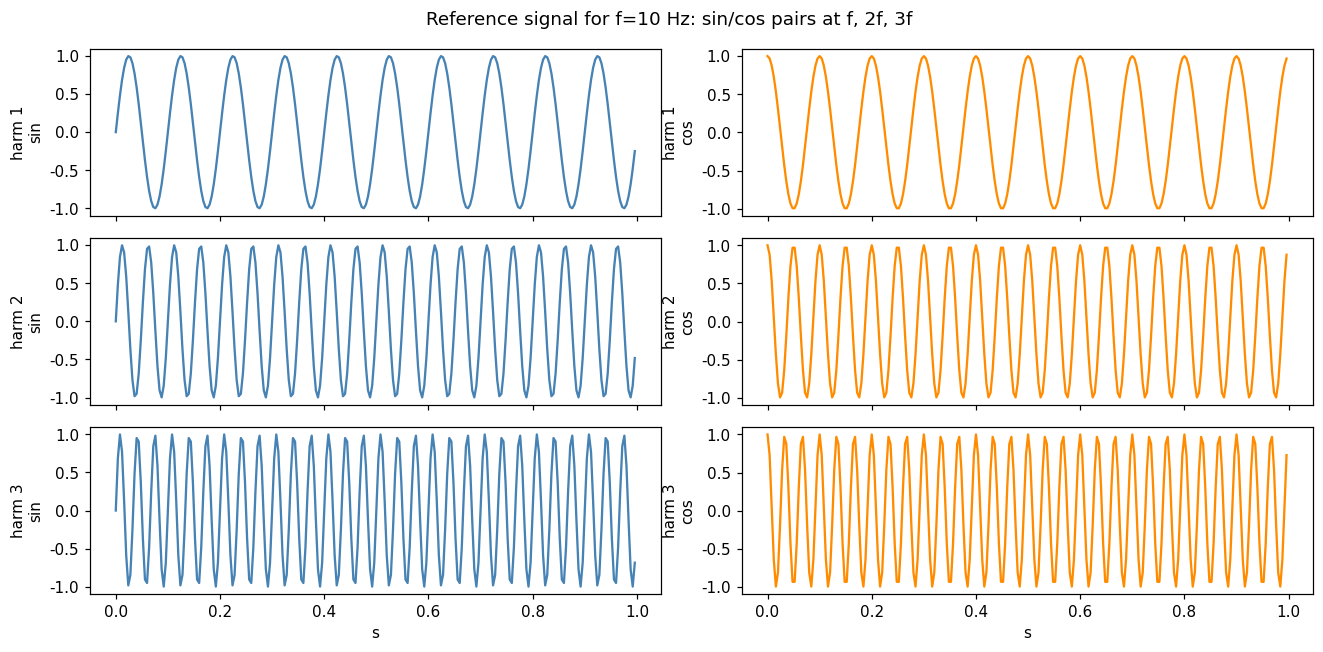

In [4]:
Y10 = reference_signal(10, 250, 250, n_harmonics=3)   # 取 1 秒便于观察
tt = np.arange(250)/250
fig, axes = plt.subplots(3, 2, figsize=(12, 6), sharex=True)
for h in range(3):
    axes[h, 0].plot(tt, Y10[2*h], color='steelblue')
    axes[h, 0].set_ylabel(f'harm {h+1}\nsin')
    axes[h, 1].plot(tt, Y10[2*h+1], color='darkorange')
    axes[h, 1].set_ylabel(f'harm {h+1}\ncos')
axes[-1, 0].set_xlabel('s'); axes[-1, 1].set_xlabel('s')
fig.suptitle('Reference signal for f=10 Hz: sin/cos pairs at f, 2f, 3f')
plt.tight_layout(); plt.show()

## 四、对 8 个候选频率打分

下面生成 8 类模拟数据，取其中一个片段，画出它对 8 个候选频率的典型相关系数。

In [5]:
def make_ssvep(n_classes=8, n_ch=9, fs=250, duration=3.0, n_trials=8,
               noise=0.6, seed=0):
    '''生成模拟 SSVEP 数据：基频+2/3 次谐波经固定空间混合，加高斯噪声。
    返回 trials(n_trials*n_classes, n_ch, T), labels, freqs。'''
    rng = np.random.default_rng(seed)
    freqs = np.arange(8.0, 8.0 + n_classes)
    T = int(fs * duration)
    t = np.arange(T) / fs
    mixing = rng.normal(size=(n_ch, 3))          # 谐波源 -> 通道 的空间混合
    phases = rng.uniform(0, 2*np.pi, size=(n_classes, 3))
    X, y = [], []
    for k, f in enumerate(freqs):
        src = np.vstack([np.sin(2*np.pi*h*f*t + phases[k, h-1]) for h in (1, 2, 3)])
        clean = mixing @ src
        for _ in range(n_trials):
            X.append(clean + noise*rng.normal(size=(n_ch, T)))
            y.append(k)
    return np.array(X), np.array(y), freqs

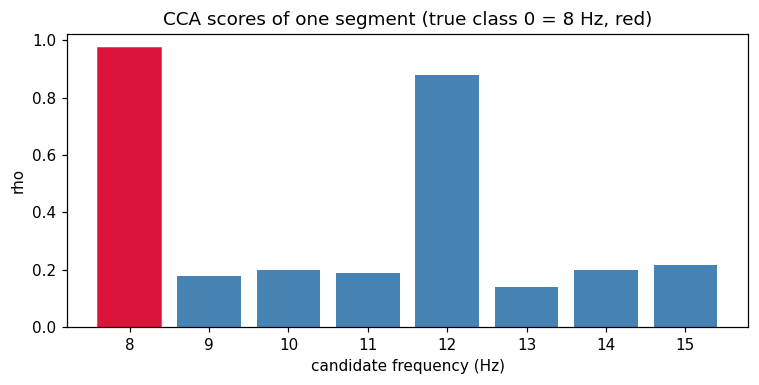

In [6]:
from ssvep.preprocess import bandpass_filter
trials, labels, freqs = make_ssvep(noise=0.8)
trials_bp = np.array([bandpass_filter(x, 250, 6.0, 80.0) for x in trials])

true_k = labels[0]
seg = trials_bp[0]
scores = [my_cca_max_corr(seg, reference_signal(f, 250, seg.shape[-1], 3))
          for f in freqs]
plt.figure(figsize=(7, 3.6))
bars = plt.bar(range(8), scores, color='steelblue')
bars[true_k].set_color('crimson')
plt.xticks(range(8), freqs.astype(int))
plt.xlabel('candidate frequency (Hz)'); plt.ylabel('rho')
plt.title(f'CCA scores of one segment (true class {true_k} = {freqs[true_k]:.0f} Hz, red)')
plt.tight_layout(); plt.show()

注意打分图中 **15 Hz 的得分有时也偏高**：这是因为 10 Hz 的 3 次谐波（30 Hz）与
15 Hz 的 2 次谐波（30 Hz）频率重合，称为**谐波混叠**。这也是谐波个数不宜盲目
增大的原因之一（见本节末的参数实验）。

## 五、工程封装与批量分类

`ssvep/cca.py` 的 `CCAClassifier` 与上面的实现完全对应，并封装了预处理与
批量预测。对全部 64 个片段分类并画混淆矩阵。

CCA 正确率 = 100.0 %


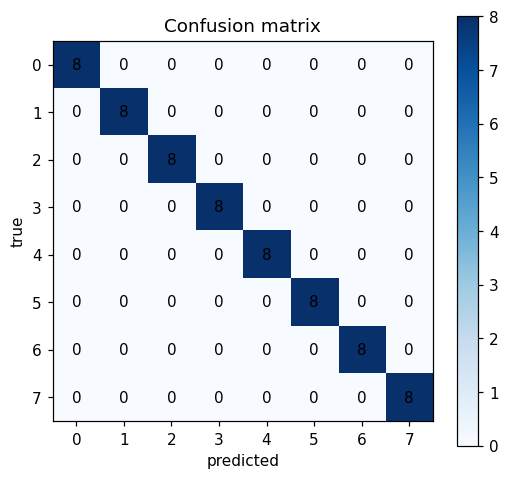

In [7]:
from ssvep import CCAClassifier
clf = CCAClassifier(freqs, 250, n_harmonics=3)
pred = clf.predict_batch(trials_bp)
acc = (pred == labels).mean()*100
print('CCA 正确率 = %.1f %%' % acc)

cm = np.zeros((8, 8), dtype=int)
for p, t in zip(pred, labels):
    cm[t, p] += 1
plt.figure(figsize=(5, 4.5))
plt.imshow(cm, cmap='Blues', vmin=0)
plt.colorbar(); plt.xlabel('predicted'); plt.ylabel('true')
plt.title('Confusion matrix')
for i in range(8):
    for j in range(8):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout(); plt.show()

## 六、谐波个数 $N_h$ 的影响

高信噪比、长窗口时谐波数影响不明显；把条件调苛刻（**强噪声 + 0.5 s 短窗口**，
5 个随机种子平均）后可以看到规律：只含基频（$N_h=1$）信息不足，$N_h=3$ 附近
最优，谐波数继续增多反而引入噪声维度。真实数据上通常取 3~5。

In [8]:
for nh in (1, 2, 3, 4, 5, 6):
    accs = []
    for seed in range(5):
        Xs, ys, frs = make_ssvep(noise=4.0, duration=2.0, seed=seed)
        w = int(0.5*250)
        clf = CCAClassifier(frs, 250, n_harmonics=nh)
        accs.append((clf.predict_batch(Xs[..., :w]) == ys).mean()*100)
    print(f'n_harmonics = {nh}   ACC = {np.mean(accs):5.1f} %')

n_harmonics = 1   ACC =  80.3 %


n_harmonics = 2   ACC =  91.9 %


n_harmonics = 3   ACC =  94.7 %


n_harmonics = 4   ACC =  93.8 %


n_harmonics = 5   ACC =  92.8 %


n_harmonics = 6   ACC =  92.8 %


## 小结

- CCA 在 EEG 与每个频率的正余弦参考信号之间找最大典型相关 $\rho_{\max}$，
  本质是一个**广义特征值问题**。
- sin/cos 成对使其对相位鲁棒；谐波数 $N_h$ 常用 3~5，需按真实数据调。
- **无需训练数据、速度极快**，适合作为比赛的第一版保底结果；
  缺点是没有利用被试个体差异，弱信号下精度有限——这正是 FBCCA / TRCA 要改进的。

下一笔记：**03 · FBCCA 滤波器组 CCA**。